Text(0.5, 1.0, 'currents right lead -left in dependency of time')

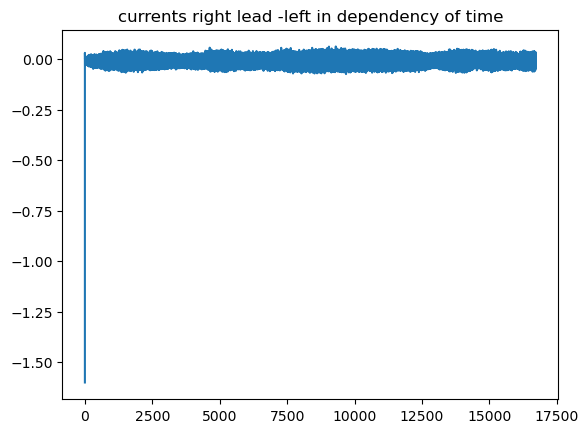

In [2]:
import numpy as np
import matplotlib.pyplot as plt

file_path = "/home/sd347/Bachelorarbeit/data/test_run/cluster_data/data0M/L10_g_coupling0.25_V5.0_w00.02_num_laps1_num_ions5_dt0.0002_1_currents.dat"

dat =np.loadtxt(file_path)
t_dat = [dat[i][0] for i in range(len(dat))]
y_dat= [dat[i,2] - dat[i,1] for i in range(len(dat))]
plt.figure()
plt.plot(t_dat, y_dat)
plt.title("currents right lead -left in dependency of time")




In [70]:
def print_data(file_name, x_data_row, y_data_row#!python counts from 0 onwards
               , labeli, line):
    data =np.loadtxt(file_name)
    t_data = [data[i][x_data_row] for i in range(len(data))]
    y_data= [data[i,y_data_row]  for i in range(len(data))]
    plt.plot(t_data, y_data, label=labeli, linestyle = line)
    
    return

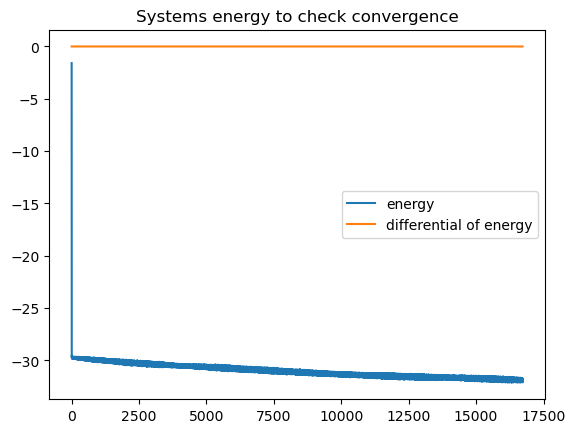

In [15]:
path_conv = "/home/sd347/Bachelorarbeit/data/test_run/cluster_data/data0M/L10_g_coupling0.25_V5.0_w00.02_num_laps1_num_ions5_dt0.0002_1_convergence_info.dat"
plt.figure()
plt.title("Systems energy to check convergence")
print_data(path_conv, 0,2, "energy" , "-")
print_data(path_conv,0, 3, "differential of energy","-")
plt.legend()

/usr/lib/python3/dist-packages/IPython/core/events.py:89: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/usr/lib/python3/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


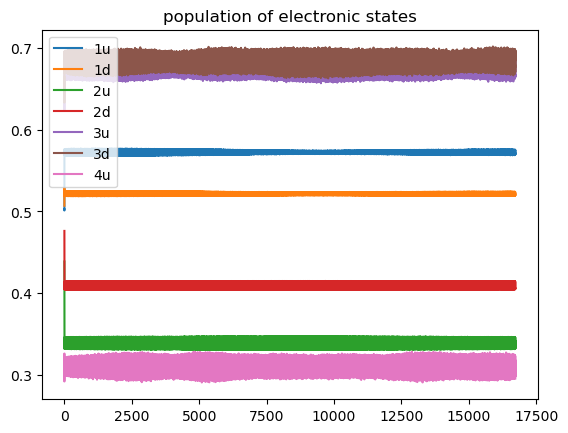

In [18]:
path_el = "/home/sd347/Bachelorarbeit/data/test_run/cluster_data/data0M/L10_g_coupling0.25_V5.0_w00.02_num_laps1_num_ions5_dt0.0002_1_electrons.dat"
plt.figure()
plt.title("population of electronic states")
print_data(path_el,0,1, "1u","-")
print_data(path_el,0, 2, "1d", "-")
print_data(path_el,0, 3, "2u", "-")
print_data(path_el,0, 4, "2d", "-")
print_data(path_el,0, 5, "3u", "-")
print_data(path_el,0, 6, "3d", "-")
print_data(path_el, 0,7, "4u", "-")
plt.legend()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


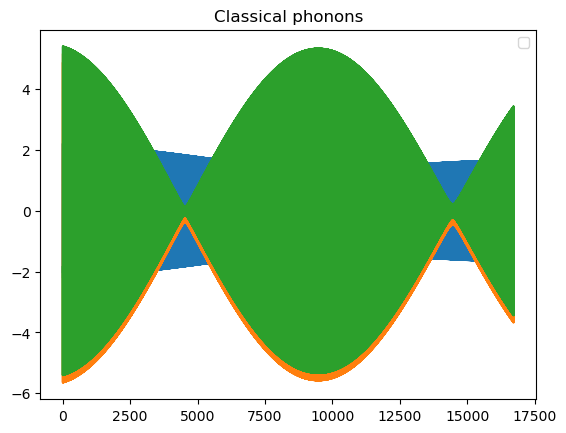

In [21]:
path_phonons = "/home/sd347/Bachelorarbeit/data/test_run/cluster_data/data0M/L10_g_coupling0.25_V5.0_w00.02_num_laps1_num_ions5_dt0.0002_1_phonons.dat"
plt.figure()
plt.title("Classical phonons")
print_data(path_phonons,0, 2, "", "-")
print_data(path_phonons,0, 3, "", "-")
print_data(path_phonons,0, 4, "", "-")
plt.legend()

In [37]:
# analytical solution
def elemente_von_U(e1, e2, lam):
    wurzel = np.sqrt((e1-e2)**2 /4 + lam**2)
    k1 = (e2+e1)/2 + wurzel
    k2 = (e2+e1)/2 - wurzel
    vy1 = -((e1-e2)/2 - wurzel + lam)/((e2-e1)/2 - wurzel + lam)
    vy2 = -((e1-e2)/2 + wurzel + lam)/((e2-e1)/2 + wurzel + lam)
    a_plus = 1/np.sqrt(1 + vy1**2)
    a_minus=  1/np.sqrt(1 + vy2**2)
    return [k1, k2, a_plus,  a_minus, vy1, vy2]

def rho1(e1, e2, lam, time, T0):
    U = elemente_von_U(e1*T0, e2*T0, lam*T0)
    #print("a_pl", U[2],"a_min", U[3],"vy1", U[4],"vy2", U[5])
    #print("rho1_ amplitude",(U[2]**4)* (U[4]**2))
    return (U[2]**4 + (U[2]**4)*(U[4]**4) + (U[2]**4)* (U[4]**2) * (2*np.cos((U[0]-U[1])*time)))

#rho1(e1, e2, lam, 0 , T0)

def rho2(e1, e2, lam, time, T0):
    U = elemente_von_U(e1*T0, e2*T0, lam*T0)
    return (U[2]**2 * U[3]**2 +   (U[2]*U[4]*U[3]*U[5])**2 + (U[2]* U[3])**2 * U[4]*U[5] * (2*np.cos((U[0]-U[1])*time)))

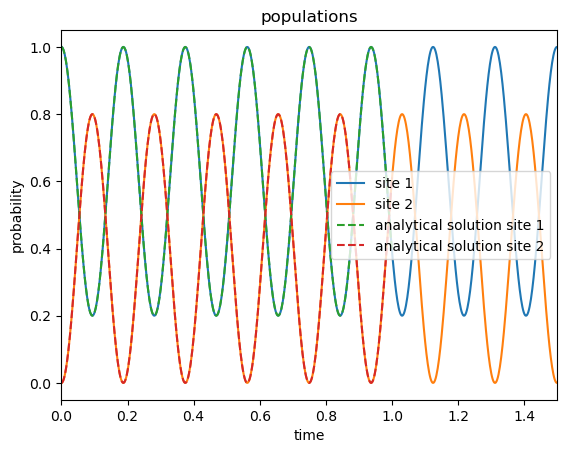

In [71]:
path_el = "/home/sd347/Bachelorarbeit/code/CISS/source/Sophia_meanfield/MeanField_v3_typed_PVar/data0M/L4_g_coupling0.0_V0.0_w00.02_num_laps1_num_ions2_dt0.0002_1_electrons.dat"
plt.figure()
plt.title("populations")
print_data(path_el,0, 1, "site 1", "-")
print_data(path_el,0, 3, "site 2", "-")


T0 = 5
e1, e2, lam = 0, 3, -3
plt.plot(np.linspace(0, 1, 300), rho1(e1, e2, lam, np.linspace(0,1, 300) , T0), label ="analytical solution site 1", linestyle = "--")
plt.plot(np.linspace(0, 1, 400), rho2(e1, e2, lam, np.linspace(0,1, 400) , T0), label ="analytical solution site 2",  linestyle = "--")

plt.legend()
plt.xlim(0,1.5)
plt.xlabel( "time")
plt.ylabel("probability")
plt.savefig("2sites_pop_check.pdf")
plt.show()





1.4142135623731051 sin(t* 0.9999999999999964 +  11.780972450961725


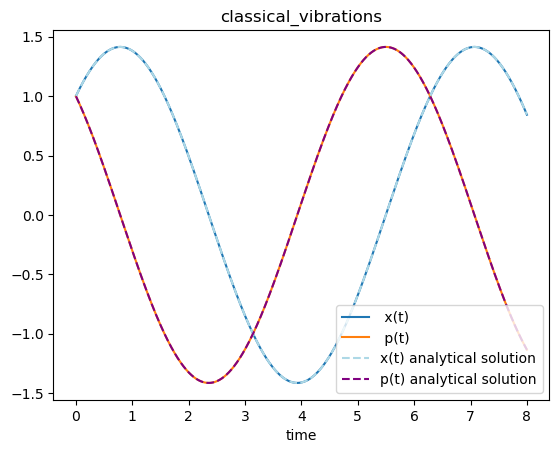

In [95]:
##checks for 2 sites, one per chain
def cos(x,  b, c, d):
    return  b*np.cos(x*c +d)

from scipy.optimize import curve_fit



path_cl_ph = "/home/sd347/Bachelorarbeit/code/CISS/source/Sophia_meanfield/MeanField_v3_typed_PVar/data0M/L4_g_coupling0.0_V0.0_w00.02_num_laps1_num_ions2_dt0.0002_1_phonons.dat"
plt.figure()
plt.title("classical_vibrations")
print_data(path_cl_ph,0, 1, " x(t)", "-")
print_data(path_cl_ph,0, 2, " p(t)", "-")

data1 =np.loadtxt(path_cl_ph)
t_data1 = [data1[i][0] for i in range(len(data1))]
#print_data(path_cl_ph,0, 3, "site 2, x(t)")


A =np.sqrt(2)
Psi = np.arccos(1/np.sqrt(2))
Psi2 = np.arcsin(1/np.sqrt(2))
plt.plot(t_data1, A*np.sin(np.array(t_data1)+ Psi ), label ="x(t) analytical solution",  linestyle = "--", color = "lightblue")
plt.plot(t_data1, A*np.cos(np.array(t_data1)+ Psi ), label ="p(t) analytical solution", linestyle = "--" ,color = "purple" )
 

#fitting numerical data in the case of x(t)

y_data1= [data1[i,1]  for i in range(len(data1))]
initial_params = [max(y_data1), 1/2*np.pi, Psi2]
params, covariance = curve_fit(cos,t_data1, y_data1, p0 = initial_params, absolute_sigma  = True )
print(params[0], "sin(t*", params[1], "+ ", params[2])
#plt.plot(t_data1, cos(np.array(t_data1), *params), label= "fit solution to numerical x")


plt.legend()
#plt.xlim(0,2)
plt.xlabel( "time")
plt.savefig("2sites_cl_vib_check.pdf")
plt.show()




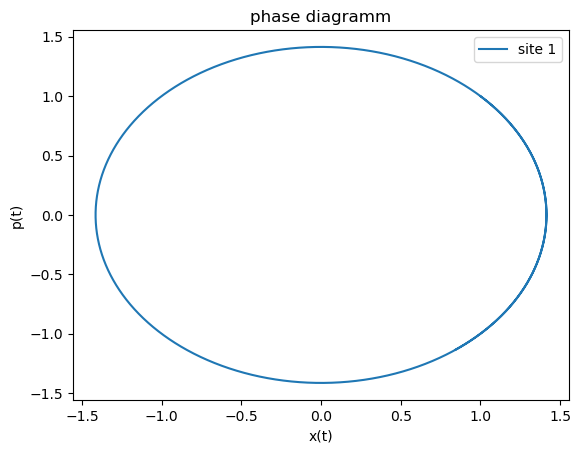

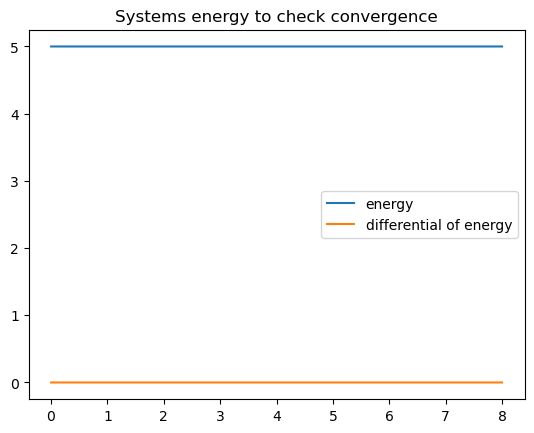

In [54]:
plt.figure
plt.title("phase diagramm")
print_data(path_cl_ph,1, 2, "site 1")
#print_data(path_cl_ph,0, 3, "site 2")
plt.legend()
#plt.xlim(0,1)
plt.xlabel( "x(t)")
plt.ylabel("p(t)")
plt.savefig("2sites_phase_dia_check.pdf")
plt.show()

path_ener = "/home/sd347/Bachelorarbeit/code/CISS/source/Sophia_meanfield/MeanField_v3_typed_PVar/data0M/L4_g_coupling0.0_V0.0_w00.02_num_laps1_num_ions2_dt0.0002_1_convergence_info.dat"
plt.figure()
plt.title("Systems energy to check convergence")
print_data(path_ener, 0,2, "energy")
print_data(path_ener,0, 3, "differential of energy")
plt.legend()
plt.savefig("2sites_energ<_check.pdf")
plt.show()

In [64]:
1/(0.02*2*np.pi)

7.957747154594767

In [65]:
1.12/(2*np.pi)

0.1782535362629228